# Linear-model theory: 1 × 4 figure

Paper figures 3. Saved results are shown by default; enable the switches below to recompute.

In [1]:
from pathlib import Path
import os
if not Path("WERM").is_dir() and Path("../WERM").is_dir():
    os.chdir("..")
assert Path("WERM").is_dir(), "Open this notebook from the repository root."
from paper_support import show_panels
RUN_EXPERIMENTS = False
REGENERATE_FIGURES = False
REGENERATE_FIGURES = REGENERATE_FIGURES or RUN_EXPERIMENTS

if REGENERATE_FIGURES:
    import numpy as np, pickle, time, logging
    import matplotlib.pyplot as plt
    from IPython.display import display
    main_logger = logging.getLogger("paper")
    Path("figures").mkdir(exist_ok=True)


In [2]:
if REGENERATE_FIGURES:
    from pathlib import Path
    import hashlib
    import json
    import numpy as np
    import matplotlib.pyplot as plt
    from linear_model_theory.linear_model_theory_lib import solve, split
    ROOT = Path.cwd()
    assert (ROOT / 'linear_model_theory/linear_model_theory_lib.py').is_file(), 'Run from the repository root.'
    OUT = ROOT / 'figures/linear_model_theory'
    OUT.mkdir(parents=True, exist_ok=True)
    SOURCE_PATHS = [ROOT / 'linear_model_theory' / name for name in ('linear_model_theory_lib.py', 'linear_model_theory_lib.py')]
    source_hashes = {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest() for p in SOURCE_PATHS}
    PAPER_WIDTH = 427.64493 / 72.27
    PAPER_STYLE = {'text.usetex': True, 'font.family': 'serif', 'font.serif': ['Computer Modern Roman'], 'font.size': 8.5, 'axes.labelsize': 10.5, 'axes.titlesize': 10.5, 'xtick.labelsize': 8.5, 'ytick.labelsize': 8.5, 'legend.fontsize': 8, 'axes.linewidth': 0.85, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': False, 'xtick.major.width': 0.85, 'ytick.major.width': 0.85, 'xtick.major.size': 3.5, 'ytick.major.size': 3.5, 'savefig.bbox': None, 'figure.dpi': 120, 'savefig.dpi': 180, 'figure.autolayout': False, 'figure.constrained_layout.use': False, 'legend.frameon': False, 'axes.formatter.useoffset': False, 'text.latex.preamble': '', 'figure.facecolor': 'white', 'axes.facecolor': 'white'}
    plt.rcParams.update(PAPER_STYLE)
    plt.close("all")


## Original calculation

In [3]:
if REGENERATE_FIGURES:
    N = 1500
    t = (np.arange(N) + 0.5) / N
    L = 3
    Phi = np.array([(1 - t) ** 2, 2 * t * (1 - t), t ** 2])
    delta = 4
    rho = 0.5
    Gam = np.array([[1, rho, rho ** 2], [rho, 1, rho], [rho ** 2, rho, 1]])

    def lim(a1, a2, sigma):
        Psi = np.where(t < a1, 0, np.where(t < a2, 1, 2))
        (b, Lam, K, v) = solve(Phi, Psi, delta, Gam, sigma)
        return (v, (split(v) - 1) / N)

    def dH(A, B):
        return max(max((min((abs(x - y) for y in B)) for x in A)), max((min((abs(x - y) for x in A)) for y in B)))
    configurations = [(0.4, 0.7), (0.1, 0.3)]
    profiles = [lim(a1, a2, 1.0) for (a1, a2) in configurations]
    g = np.linspace(0.05, 0.95, 37)
    sigmas = [1.0, 0.3]
    heatmaps = []
    for sigma in sigmas:
        H = np.full((len(g), len(g)), np.nan)
        for (i, a1) in enumerate(g):
            for (j, a2) in enumerate(g):
                if a2 - a1 >= 0.049:
                    H[j, i] = dH((a1, a2), lim(a1, a2, sigma)[1])
        heatmaps.append(H)
    for (alpha, (_, tau)) in zip(configurations, profiles):
        pass
    plt.close("all")


## Compact 1 × 4 layout

In [4]:
if REGENERATE_FIGURES:
    ROW_STYLE = {**PAPER_STYLE, 'font.size': 10, 'axes.labelsize': 12, 'axes.titlesize': 10, 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'legend.fontsize': 9, 'axes.linewidth': 1.1, 'xtick.major.width': 1.1, 'ytick.major.width': 1.1, 'xtick.major.size': 4, 'ytick.major.size': 4, 'xtick.major.pad': 2, 'ytick.major.pad': 2, 'axes.labelpad': 2}
    with plt.rc_context(ROW_STYLE):
        (fig_row, axes_row) = plt.subplots(1, 4, figsize=(7.6, 2.35))
        fig_row.subplots_adjust(left=0.045, right=0.935, bottom=0.195, top=0.826, wspace=0.27)
        group_gap_extra = 0.025
        positions = [ax.get_position().frozen() for ax in axes_row]
        pair_gap = positions[1].x0 - positions[0].x1
        panel_width = positions[0].width - group_gap_extra / 4
        for (k, ax) in enumerate(axes_row):
            left = positions[0].x0 + k * (panel_width + pair_gap) + (group_gap_extra if k >= 2 else 0)
            ax.set_position([left, positions[k].y0, panel_width, positions[k].height])
        for (k, ((a1, a2), (v, tau))) in enumerate(zip(configurations, profiles)):
            ax = axes_row[k]
            for ell in range(L):
                ax.plot(t, v[:, ell], color=['#1f77b4', '#ff7f0e', '#2ca02c'][ell], linewidth=2.0, label=f'$v_{ell + 1}(t)$')
            for a in (a1, a2):
                ax.axvline(a, color='k', ls='--', lw=1.2)
            for s in tau:
                ax.axvline(s, color='r', ls=':', lw=1.8)
            ax.set_xlabel('$t$')
            ax.set_xticks([0, 0.5, 1], labels=['0', '0.5', '1'])
            ax.set_yticks([1, 2] if k == 0 else [1, 2, 3])
            ax.set_title(f'$(\\alpha_1,\\alpha_2)=({a1},{a2})$' + '\n' + '$\\sigma=1$', pad=5)
            if k == 1:
                ax.legend(loc='upper right', frameon=False, handlelength=1.1, labelspacing=0.15, handletextpad=0.35, borderaxespad=0.25)
        for (k, (sigma, H)) in enumerate(zip(sigmas, heatmaps)):
            ax = axes_row[k + 2]
            im = ax.imshow(H, origin='lower', extent=[g[0], g[-1], g[0], g[-1]], cmap='viridis', aspect='auto', vmin=0, vmax=0.6, interpolation='nearest')
            ax.set_xlabel('$\\alpha_1$')
            ax.set_ylabel('$\\alpha_2$', labelpad=0)
            ax.set_xticks([0.2, 0.5, 0.8])
            ax.set_yticks([0.2, 0.5, 0.8])
            ax.set_title('$d_H(\\tau^*,\\alpha)$' + '\n' + f'$\\sigma={sigma}$', pad=5)
        bottom_box = axes_row[3].get_position()
        cax = fig_row.add_axes([0.95, bottom_box.y0, 0.012, bottom_box.height])
        colorbar = fig_row.colorbar(im, cax=cax, ticks=np.linspace(0, 0.6, 4))
        fig_row.canvas.draw()
        renderer = fig_row.canvas.get_renderer()
        for ax in fig_row.axes:
            box = ax.get_tightbbox(renderer)
            assert box.x0 >= 0 and box.y0 >= 0
            assert box.x1 <= fig_row.bbox.width and box.y1 <= fig_row.bbox.height
        for extension in ('pdf', 'png'):
            fig_row.savefig(OUT / f'linear_model_limit_1x4.{extension}', bbox_inches=None, dpi=300)
    for (k, (v, tau)) in enumerate(profiles):
        for ell in range(L):
            np.testing.assert_array_equal(axes_row[k].lines[ell].get_xdata(), t)
            np.testing.assert_array_equal(axes_row[k].lines[ell].get_ydata(), v[:, ell])
        for (line, location) in zip(axes_row[k].lines[3:], [*configurations[k], *tau]):
            np.testing.assert_array_equal(line.get_xdata(), [location, location])
    for (k, H) in enumerate(heatmaps):
        image = axes_row[k + 2].images[0]
        np.testing.assert_array_equal(image.get_array().filled(np.nan), H)
        np.testing.assert_array_equal(image.get_extent(), [g[0], g[-1], g[0], g[-1]])
        assert image.get_clim() == (0, 0.6)
        assert image.get_cmap().name == 'viridis'
    plt.close(fig_row)
    fig_row
    plt.close("all")


## Figure 3

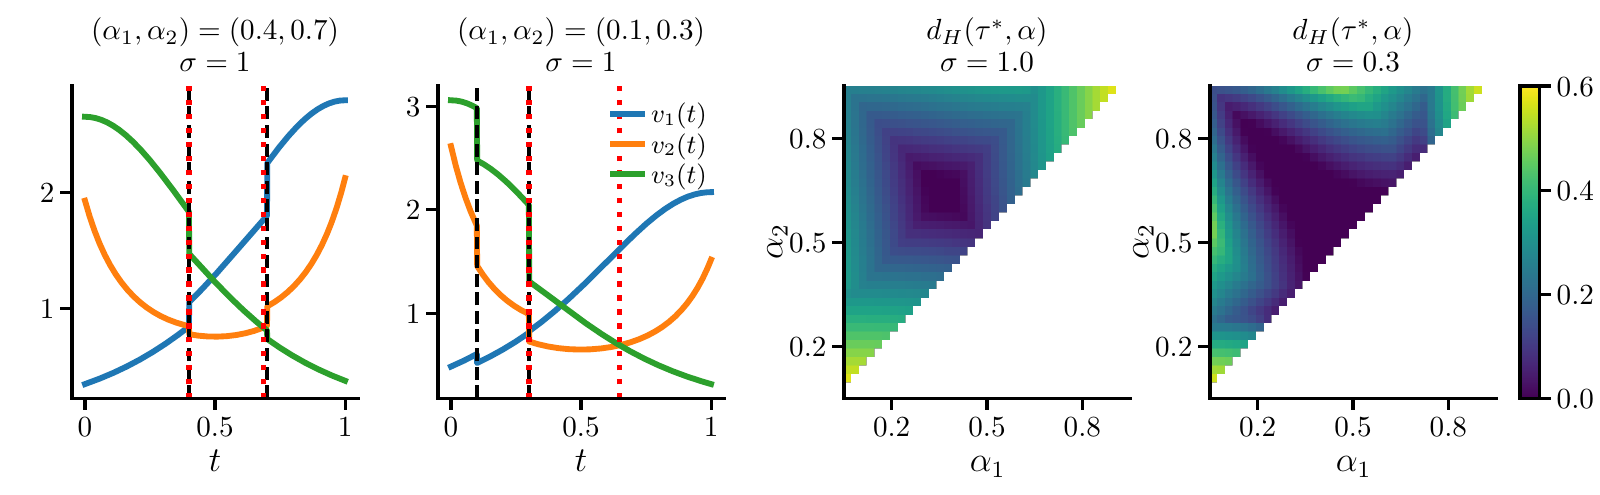

In [5]:
panels = ['figures/linear_model_theory/linear_model_limit_1x4.pdf'] if REGENERATE_FIGURES else ['figures/figure_03/panel_01.pdf']
show_panels(panels)
